In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

## Training Data set

In [2]:
x1 = [0,0,1,1]
x2   = [0,1,0,1]

OR

In [3]:
Result      =  [0,  1, 1, 1] # 1 = pass, 0 = fail

AND

In [16]:
Result      =  [0,  0, 0, 1] # 1 = pass, 0 = fail

XOR

In [23]:
Result      =  [0,  1, 1, 0] # 1 = pass, 0 = fail

## Ploting Train Data set.
ploting data points using seaborn (Seaborn requires dataframe)

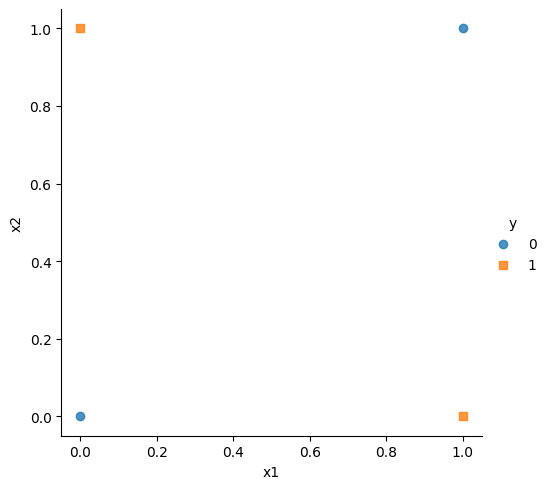

In [24]:
df = pd.DataFrame({
    'x1': x1,
    'x2': x2,
    'y': Result
})

sns.lmplot(
    data=df,
    x='x1',
    y='x2',
    hue='y',
    fit_reg=False,
    markers=['o', 's']
)

plt.show()

## Activation Function

In [25]:
def step_function(x):
    if x<0:
        return 0
    else:
        return 1

def sigmoid_function(x):
  return 1 / (1 + np.exp(-x))

## Parameter Initialization

In [26]:
#w = np.random.rand(2)
w = np.array([1,-1])
errors = []
eta = .90   # learning rate
epoch = 10
b = 0

## Learning

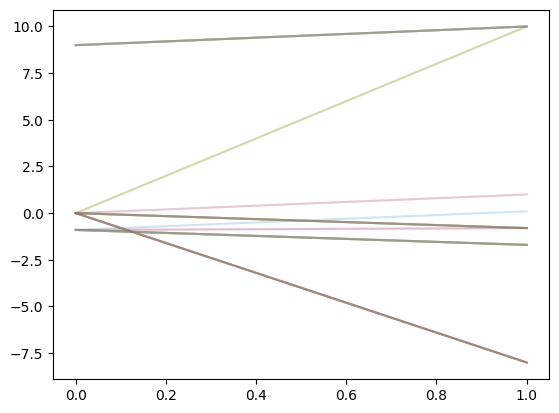

In [27]:
# وزن‌ها اعشاری باشند تا تغییرات اعشاری حفظ شوند
w = np.asarray(w, dtype=float)

for i in range(epoch):
    for x, y in zip(zip(x1, x2), Result):
        x = np.asarray(x, dtype=float)

        u = np.dot(x, w) + b
        error = y - step_function(u)
        errors.append(error)

        # به‌روزرسانی وزن‌ها
        for index, value in enumerate(x):
            w[index] += eta * error * value

        # یک بار برای هر نمونه
        b += eta * error

        plt.figure(1)

        if w[1] != 0:
            xs = np.array([min(x1), max(x1)])
            ys = -(w[0] * xs + b) / w[1]
            plt.plot(xs, ys, alpha=0.2)
        elif w[0] != 0:
            plt.axvline(-b / w[0], alpha=0.2)

# Ploting Final decision boundary

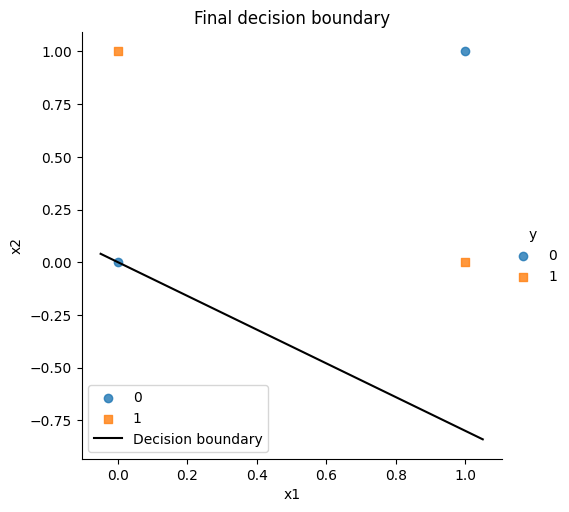

In [28]:
# رسم نقاط داده
g = sns.lmplot(
    data=df,
    x='x1',
    y='x2',
    hue='y',
    fit_reg=False,
    markers=['o', 's']
)

ax = g.ax

# رسم مرز تصمیم: w[0]*x1 + w[1]*x2 + b = 0
if w[1] != 0:
    xs = np.array(ax.get_xlim())
    ys = -(w[0] * xs + b) / w[1]

    ax.plot(xs, ys, color='black', label='Decision boundary')

elif w[0] != 0:
    ax.axvline(
        x=-b / w[0],
        color='black',
        label='Decision boundary'
    )

else:
    print("هر دو وزن صفر هستند؛ مرز تصمیم قابل رسم نیست.")

ax.set_title('Final decision boundary')
ax.legend()
plt.show()

# Ploting errors

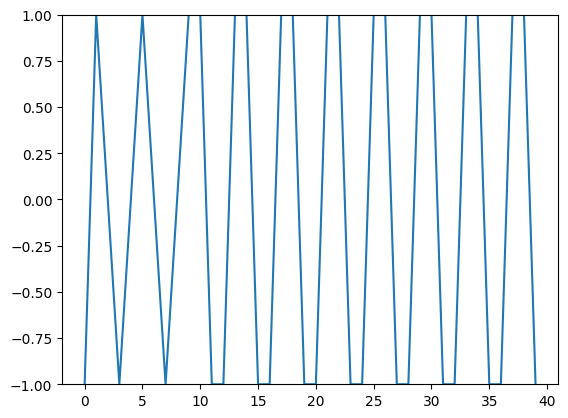

In [29]:
plt.figure(3)
plt.ylim([-1,1])
plt.plot(errors)

In [ ]:
assign_input = int(input("enter Assignment number"))
exam_input = int(input("enter Exam number"))

input_numbers = (assign_input,exam_input)

print(input_numbers)

u1 = w[0]*assign_input + w[1]*exam_input + b
print(step_function(u1))
print(sigmoid_function(u1))
